<a href="https://colab.research.google.com/github/RunCoderRun/ChallengeAmigoSecretoAluraONE/blob/main/AluraStoreBr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Importação dos dados



In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_1.csv"
url2 = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_2.csv"
url3 = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_3.csv"
url4 = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_4.csv"

loja = pd.read_csv(url)
loja2 = pd.read_csv(url2)
loja3 = pd.read_csv(url3)
loja4 = pd.read_csv(url4)

loja.head()

,Produto,Categoria do Produto,Preço,Frete,Data da Compra,Vendedor,Local da compra,Avaliação da compra,Tipo de pagamento,Quantidade de parcelas,lat,lon
0,Assistente virtual,eletronicos,219.08,9.249790,16/01/2021,Pedro Gomes,SP,4,cartao_credito,8,-22.19,-48.79
1,Mesa de jantar,moveis,256.35,11.234305,18/05/2022,Beatriz Moraes,RJ,1,cartao_credito,4,-22.25,-42.66
2,Jogo de tabuleiro,brinquedos,279.51,21.262681,15/03/2021,João Souza,DF,1,cartao_credito,1,-15.83,-47.86
3,Micro-ondas,eletrodomesticos,1009.99,54.667344,03/05/2022,João Souza,RS,4,boleto,1,-30.17,-53.50
4,Cadeira de escritório,moveis,446.99,26.964689,07/11/2020,Larissa Alves,MG,5,boleto,1,-18.10,-44.38


#1. Análise do faturamento


Faturamento Total: 5871490.790000001

Faturamento Mensal:
Data da Compra
2020-01    143060.68
2020-02    143867.81
2020-03    160848.48
2020-04    181531.80
2020-05    162879.36
2020-06    128893.49
2020-07    158880.06
2020-08    148909.59
2020-09    154987.12
2020-10    120876.93
2020-11    134062.76
2020-12    150474.29
2021-01    134539.67
2021-02    148227.40
2021-03    159902.67
2021-04    160804.09
2021-05    136728.55
2021-06    136928.76
2021-07    177333.33
2021-08    169677.42
2021-09    160527.87
2021-10    153600.98
2021-11    175478.87
2021-12    185071.37
2022-01    189308.00
2022-02    144292.72
2022-03    138687.27
2022-04    141467.01
2022-05    150346.35
2022-06    128951.85
2022-07    128641.37
2022-08    148761.85
2022-09    173675.52
2022-10    123490.77
2022-11    147080.67
2022-12    155230.35
2023-01    128435.36
2023-02    145069.07
2023-03    139959.28
Freq: M, Name: Preço, dtype: float64

Faturamento por Loja:
ID_Loja
loja_1    1534509.12
loja_2    1488459.0

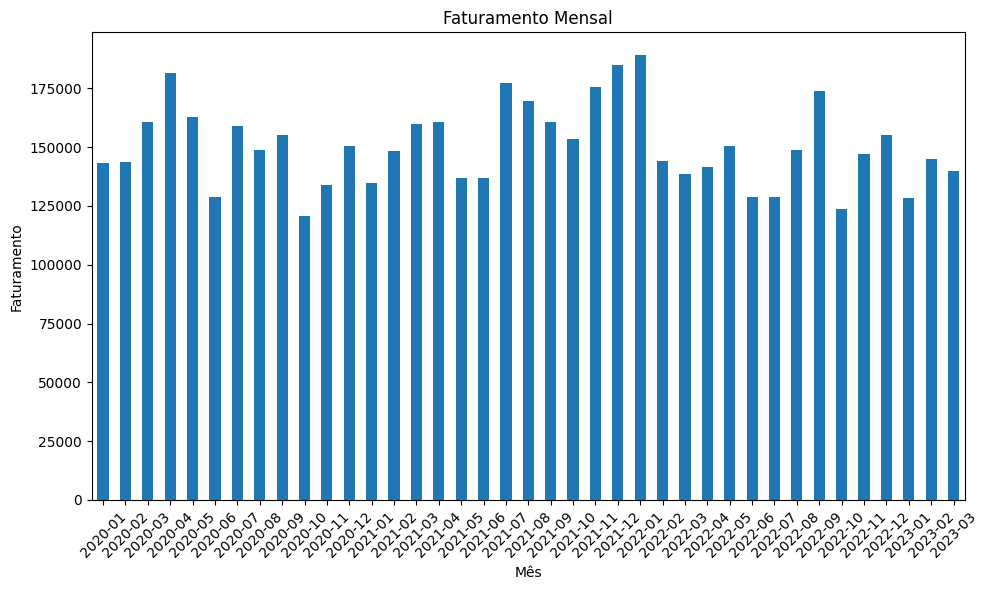

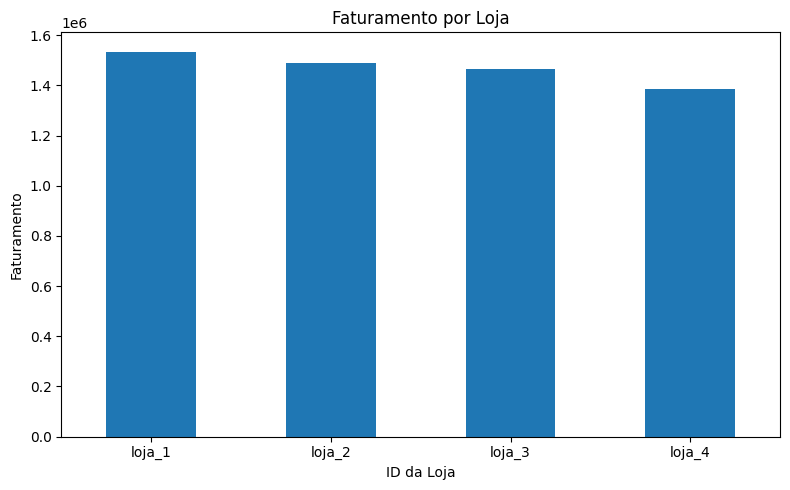

In [4]:
# prompt: Analisar o faturamento a partir dos três arquivos ".csv" anexados

import pandas as pd
### Combinando os DataFrames
dados_faturamento = pd.concat([loja, loja2, loja3, loja4])

### Convertendo a coluna 'Data da Compra' para datetime
dados_faturamento['Data da Compra'] = pd.to_datetime(dados_faturamento['Data da Compra'], format='%d/%m/%Y')

### Calculando o faturamento total
faturamento_total = dados_faturamento['Preço'].sum()

### Calculando o faturamento mensal
faturamento_mensal = dados_faturamento.groupby(dados_faturamento['Data da Compra'].dt.to_period('M'))['Preço'].sum()

### Calculando o faturamento por loja
# Assuming there is a column that identifies the store, let's add a 'ID_Loja' column during concatenation
loja['ID_Loja'] = 'loja_1'
loja2['ID_Loja'] = 'loja_2'
loja3['ID_Loja'] = 'loja_3'
loja4['ID_Loja'] = 'loja_4'

dados_faturamento = pd.concat([loja, loja2, loja3, loja4])

faturamento_por_loja = dados_faturamento.groupby('ID_Loja')['Preço'].sum()


### Exibindo os resultados
print("Faturamento Total:", faturamento_total)
print("\nFaturamento Mensal:")
print(faturamento_mensal)
print("\nFaturamento por Loja:")
print(faturamento_por_loja)

### Visualização do faturamento mensal (opcional)
import matplotlib.pyplot as plt

faturamento_mensal.plot(kind='bar', figsize=(10, 6))
plt.title('Faturamento Mensal')
plt.xlabel('Mês')
plt.ylabel('Faturamento')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Visualização do faturamento por loja (opcional)
faturamento_por_loja.plot(kind='bar', figsize=(8, 5))
plt.title('Faturamento por Loja')
plt.xlabel('ID da Loja')
plt.ylabel('Faturamento')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Vendas por Categoria



Vendas por Categoria:
Categoria do Produto
eletronicos              2214099.72
eletrodomesticos         1766337.03
moveis                   1010214.00
instrumentos musicais     465029.67
esporte e lazer           190635.39
brinquedos                 98140.86
utilidades domesticas      76773.38
livros                     50260.74
Name: Preço, dtype: float64


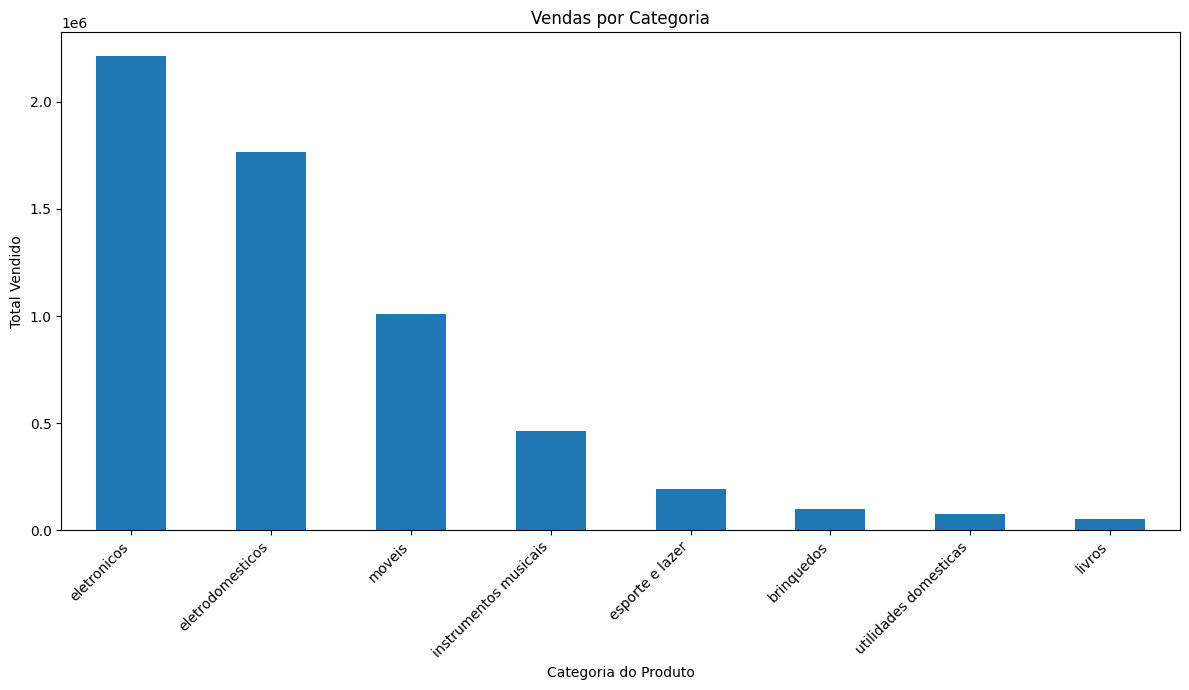

In [6]:
# prompt: Código em python para analisar "Vendas por Categoria" exibir graficamente

import matplotlib.pyplot as plt
# Análise de Vendas por Categoria
vendas_por_categoria = dados_faturamento.groupby('Categoria do Produto')['Preço'].sum().sort_values(ascending=False)

print("\nVendas por Categoria:")
print(vendas_por_categoria)

# Visualização das Vendas por Categoria
vendas_por_categoria.plot(kind='bar', figsize=(12, 7))
plt.title('Vendas por Categoria')
plt.xlabel('Categoria do Produto')
plt.ylabel('Total Vendido')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 3. Média de Avaliação das Lojas


Média de Avaliação por Loja:
ID_Loja
loja_1    3.976685
loja_2    4.037304
loja_3    4.048326
loja_4    3.995759
Name: Avaliação da compra, dtype: float64


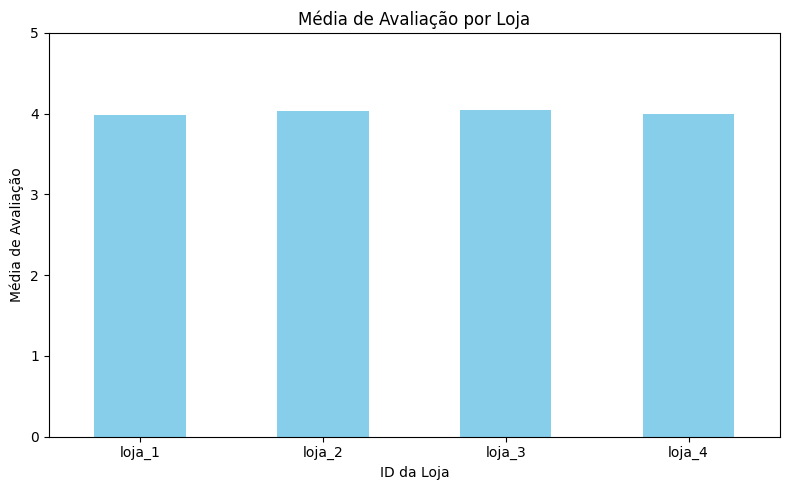

In [14]:
import matplotlib.pyplot as plt
# Análise da Média de Avaliação das Lojas
media_avaliacao_por_loja = dados_faturamento.groupby('ID_Loja')['Avaliação da compra'].mean()

print("\nMédia de Avaliação por Loja:")
print(media_avaliacao_por_loja)

# Visualização da Média de Avaliação das Lojas
media_avaliacao_por_loja.plot(kind='bar', figsize=(8, 5), color='skyblue')
plt.title('Média de Avaliação por Loja')
plt.xlabel('ID da Loja')
plt.ylabel('Média de Avaliação')
plt.xticks(rotation=0)
plt.ylim(0, 5) # Assuming evaluation is on a scale of 1 to 5
plt.tight_layout()
plt.show()

# 4. Produtos Mais e Menos Vendidos


Top 10 Produtos Mais Vendidos:
Produto
Cômoda                      210
Carrinho controle remoto    206
Micro-ondas                 206
Bateria                     203
Cama king                   201
Secadora de roupas          200
Modelagem preditiva         200
Jogo de panelas             200
Cama box                    199
Blocos de montar            199
Name: count, dtype: int64


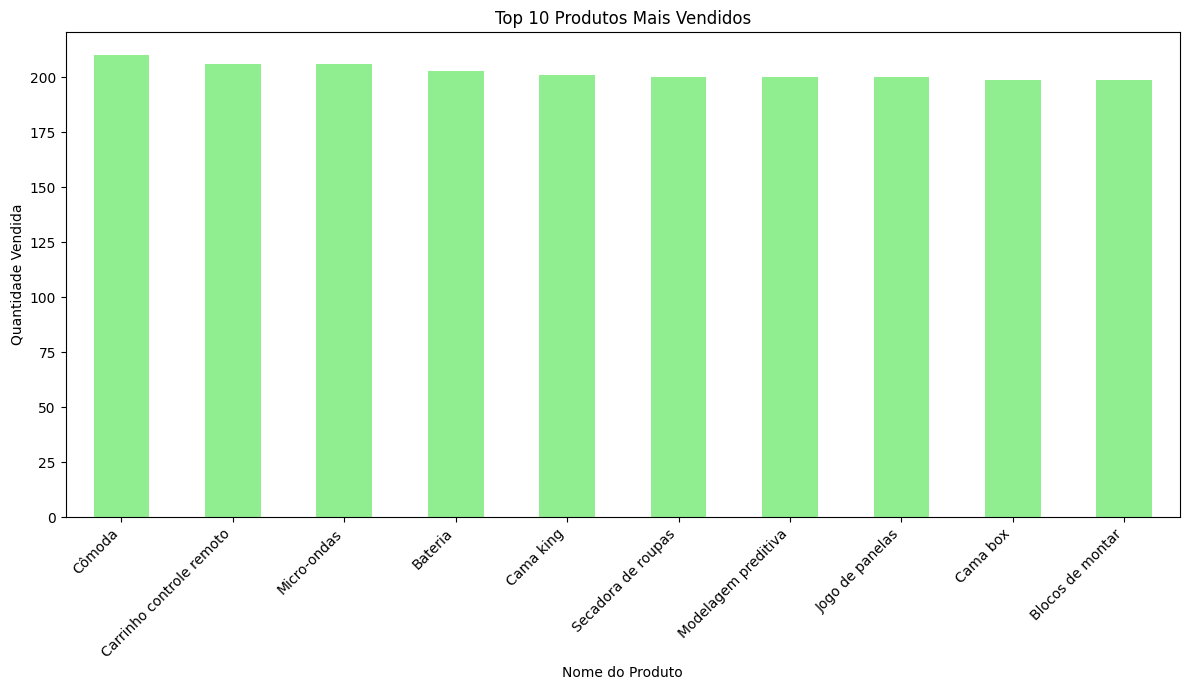


Top 10 Produtos Menos Vendidos:
Produto
Panela de pressão              172
Smartwatch                     172
Jogo de copos                  169
Poltrona                       168
Assistente virtual             167
Ciência de dados com python    166
Guitarra                       165
Mochila                        163
Headset                        158
Celular ABXY                   157
Name: count, dtype: int64


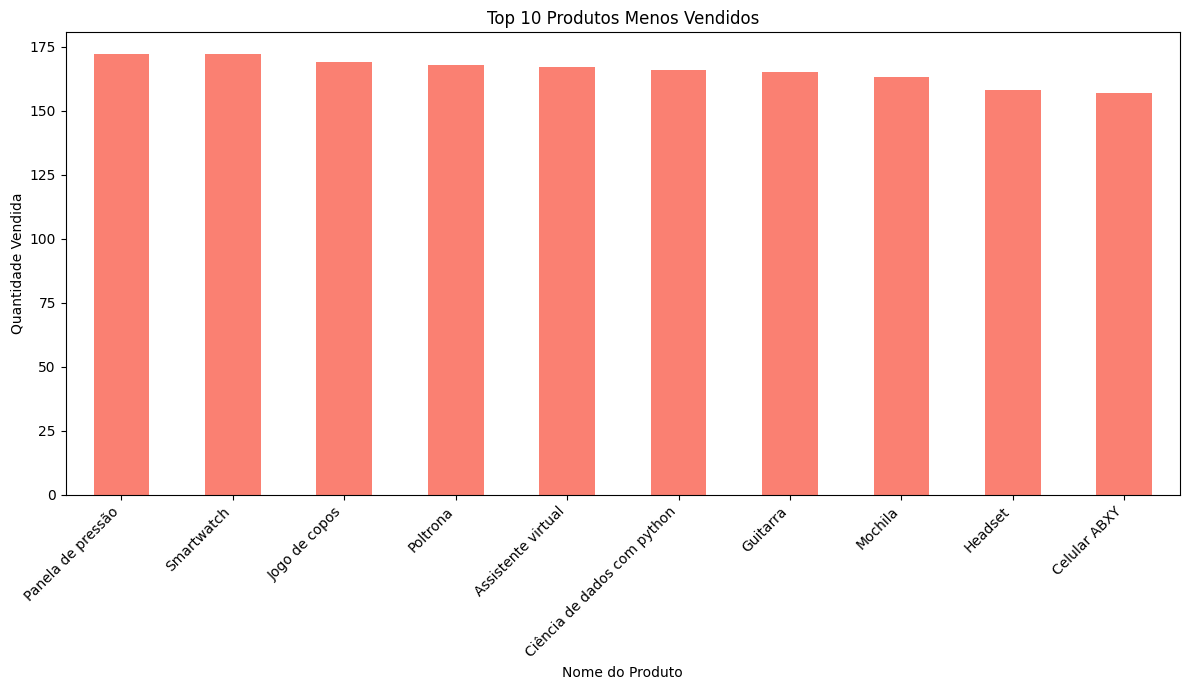

In [13]:
import matplotlib.pyplot as plt
# Produtos Mais Vendidos
produtos_mais_vendidos = dados_faturamento['Produto'].value_counts().head(10)

print("\nTop 10 Produtos Mais Vendidos:")
print(produtos_mais_vendidos)

# Visualização dos Produtos Mais Vendidos
produtos_mais_vendidos.plot(kind='bar', figsize=(12, 7), color='lightgreen')
plt.title('Top 10 Produtos Mais Vendidos')
plt.xlabel('Nome do Produto')
plt.ylabel('Quantidade Vendida')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# Produtos Menos Vendidos
produtos_menos_vendidos = dados_faturamento['Produto'].value_counts().tail(10)

print("\nTop 10 Produtos Menos Vendidos:")
print(produtos_menos_vendidos)

# Visualização dos Produtos Menos Vendidos
produtos_menos_vendidos.plot(kind='bar', figsize=(12, 7), color='salmon')
plt.title('Top 10 Produtos Menos Vendidos')
plt.xlabel('Nome do Produto')
plt.ylabel('Quantidade Vendida')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 5. Frete Médio por Loja



Frete Médio por Loja:
ID_Loja
loja_1    34.691805
loja_2    33.621941
loja_3    33.074464
loja_4    31.278997
Name: Frete, dtype: float64


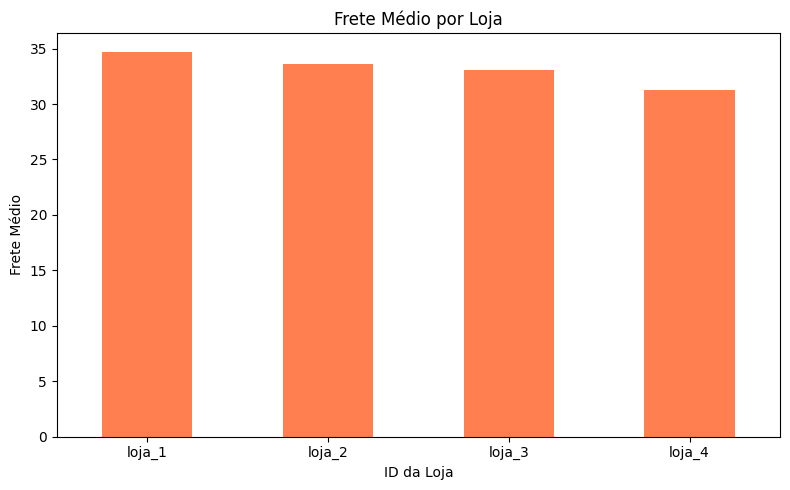

In [15]:
# prompt: Frete Médio por Loja

import matplotlib.pyplot as plt
# Análise do Frete Médio por Loja
frete_medio_por_loja = dados_faturamento.groupby('ID_Loja')['Frete'].mean()

print("\nFrete Médio por Loja:")
print(frete_medio_por_loja)

# Visualização do Frete Médio por Loja
frete_medio_por_loja.plot(kind='bar', figsize=(8, 5), color='coral')
plt.title('Frete Médio por Loja')
plt.xlabel('ID da Loja')
plt.ylabel('Frete Médio')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()